# Graph Compilation, Visualization, and Runtime Invocation
**Production Reference Implementation (Senior AI Engineer Standard)**

## Architectural Scope
This notebook establishes production patterns for assembling, introspecting, rendering, and invoking stateful workflows using **LangGraph**.
It covers:
1. Declarative workflow construction via `StateGraph`.
2. Static graph compilation mechanics and channel initialization via `.compile()`.
3. Graph AST introspection and visual rendering via `get_graph().draw_mermaid_png()`.
4. Deterministic and stochastic invocation lifecycles (`invoke()` vs `stream()`).
5. Multi-run branch traversal and output state accumulation.
6. Programmatic validation assertions ensuring deterministic state transitions.


In [1]:
import random
from typing import Dict, Any, Literal
from typing_extensions import TypedDict
from IPython.display import Image, display

from langgraph.graph import StateGraph, START, END

print("LangGraph core classes and IPython visualization utilities imported successfully.")


LangGraph core classes and IPython visualization utilities imported successfully.


## 1. Graph State Schema and Computational Nodes
We define the canonical state schema using `TypedDict` and implement isolated functional nodes
that consume the current state snapshot and return partial delta dictionaries.


In [2]:
class PlayState(TypedDict):
    """Canonical state contract across workflow nodes."""
    graph_info: str

def start_play(state: PlayState) -> Dict[str, Any]:
    """Entry node initializing intent and appending planning text."""
    current = state.get("graph_info", "")
    print(f"[Node: start_play] Processing input: '{current}'")
    updated = f"{current} I am planning to play".strip()
    return {"graph_info": updated}

def cricket(state: PlayState) -> Dict[str, Any]:
    """Terminal branch node for cricket activity."""
    current = state.get("graph_info", "")
    print(f"[Node: cricket] Appending cricket selection.")
    return {"graph_info": f"{current} cricket"}

def badminton(state: PlayState) -> Dict[str, Any]:
    """Terminal branch node for badminton activity."""
    current = state.get("graph_info", "")
    print(f"[Node: badminton] Appending badminton selection.")
    return {"graph_info": f"{current} badminton"}

print("State schema and computational nodes defined successfully.")


State schema and computational nodes defined successfully.


## 2. Conditional Routing Function
The routing function evaluates state attributes or stochastic conditions
and returns a string constrained by `typing.Literal` matching valid node names.


In [3]:
def random_play(state: PlayState) -> Literal["cricket", "badminton"]:
    """Decider function evaluating branching conditions."""
    threshold = random.random()
    decision: Literal["cricket", "badminton"] = "cricket" if threshold > 0.5 else "badminton"
    print(f"[Decider: random_play] Sampled value {threshold:.3f} -> Routing to: '{decision}'")
    return decision

print("Conditional routing function defined with return type Literal['cricket', 'badminton'].")


Conditional routing function defined with return type Literal['cricket', 'badminton'].


## 3. Graph Assembly and Static Compilation
We register nodes, declare direct edges from `START`, bind conditional branching,
connect terminal sink transitions to `END`, and compile the executable artifact.


In [4]:
# 1. Instantiate state graph
builder = StateGraph(PlayState)

# 2. Register functional nodes
builder.add_node("start_play", start_play)
builder.add_node("cricket", cricket)
builder.add_node("badminton", badminton)

# 3. Schedule workflow transitions
builder.add_edge(START, "start_play")
builder.add_conditional_edges(
    "start_play",
    random_play,
    {
        "cricket": "cricket",
        "badminton": "badminton"
    }
)
builder.add_edge("cricket", END)
builder.add_edge("badminton", END)

# 4. Compile into executable runnable
app = builder.compile()

print("Graph assembled and compiled successfully. Compiled runnable type:", type(app).__name__)


Graph assembled and compiled successfully. Compiled runnable type: CompiledStateGraph


## 4. Visual Topology Inspection via Mermaid
We inspect the compiled graph AST using `.get_graph()` and render the visual flowchart.


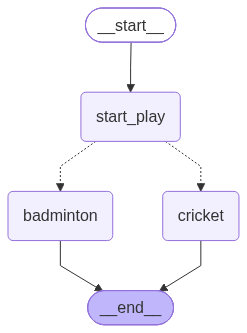

Visual Mermaid diagram rendered successfully (11105 bytes).


In [5]:
graph_ast = app.get_graph()

# Render visual diagram if environment supports image display
try:
    png_bytes = graph_ast.draw_mermaid_png()
    display(Image(png_bytes))
    print(f"Visual Mermaid diagram rendered successfully ({len(png_bytes)} bytes).")
except Exception as e:
    print(f"Graphical PNG render unavailable ({e}); falling back to Mermaid markdown:")
    print(graph_ast.draw_mermaid())


## 5. Runtime Invocation Lifecycle and Multi-Run Verification
We invoke the compiled graph using `.invoke()` and execute multiple trials
to observe runtime traversal across both probabilistic branches.


In [6]:
# Trial 1: Standard invocation
input_payload = {"graph_info": "Hi, my name is Krish."}
print("Executing Trial 1 Invocation:")
print("-" * 50)
result_1 = app.invoke(input_payload)
print("Trial 1 Result:", result_1["graph_info"])

# Execute subsequent trials to verify branching stochasticity
print("\nExecuting Multiple Trials to Verify Branch Diversity:")
print("-" * 50)
observed_destinations = set()
for trial in range(1, 11):
    trial_res = app.invoke({"graph_info": f"Trial {trial}:"})
    last_word = trial_res["graph_info"].split()[-1]
    observed_destinations.add(last_word)
    print(f"  Trial {trial:02d} Destination: {last_word}")

print(f"\nObserved Target Destinations Across 10 Trials: {observed_destinations}")


Executing Trial 1 Invocation:
--------------------------------------------------
[Node: start_play] Processing input: 'Hi, my name is Krish.'
[Decider: random_play] Sampled value 0.301 -> Routing to: 'badminton'
[Node: badminton] Appending badminton selection.
Trial 1 Result: Hi, my name is Krish. I am planning to play badminton

Executing Multiple Trials to Verify Branch Diversity:
--------------------------------------------------
[Node: start_play] Processing input: 'Trial 1:'
[Decider: random_play] Sampled value 0.325 -> Routing to: 'badminton'
[Node: badminton] Appending badminton selection.
  Trial 01 Destination: badminton
[Node: start_play] Processing input: 'Trial 2:'
[Decider: random_play] Sampled value 0.489 -> Routing to: 'badminton'
[Node: badminton] Appending badminton selection.
  Trial 02 Destination: badminton
[Node: start_play] Processing input: 'Trial 3:'
[Decider: random_play] Sampled value 0.004 -> Routing to: 'badminton'
[Node: badminton] Appending badminton selec

## 6. Incremental Superstep Streaming vs Batch Execution
We demonstrate `.stream()` to yield discrete state mutations per superstep.


In [7]:
print("Executing Incremental Superstep Stream:")
print("=" * 60)

streamed_steps = []
for idx, superstep in enumerate(app.stream({"graph_info": "Stream Test:"})):
    for node_name, state_delta in superstep.items():
        print(f"Step {idx + 1} -> Node: [{node_name}] | State Delta: {state_delta}")
        streamed_steps.append(node_name)

print("=" * 60)
print("Streamed Node Sequence:", streamed_steps)


Executing Incremental Superstep Stream:
[Node: start_play] Processing input: 'Stream Test:'
[Decider: random_play] Sampled value 0.816 -> Routing to: 'cricket'
Step 1 -> Node: [start_play] | State Delta: {'graph_info': 'Stream Test: I am planning to play'}
[Node: cricket] Appending cricket selection.
Step 2 -> Node: [cricket] | State Delta: {'graph_info': 'Stream Test: I am planning to play cricket'}
Streamed Node Sequence: ['start_play', 'cricket']


## 7. Programmatic Invariant Assertions
Defensive validation confirming graph topology invariants, compilation stability, and output accuracy.


In [8]:
# 1. Verify graph node registration count
nodes_in_graph = list(graph_ast.nodes.keys())
assert "__start__" in nodes_in_graph, "Assertion Failed: __start__ missing."
assert "__end__" in nodes_in_graph, "Assertion Failed: __end__ missing."
assert "start_play" in nodes_in_graph, "Assertion Failed: start_play missing."
assert "cricket" in nodes_in_graph, "Assertion Failed: cricket missing."
assert "badminton" in nodes_in_graph, "Assertion Failed: badminton missing."

# 2. Verify state propagation and string concatenation
final_str = result_1["graph_info"]
assert "Hi, my name is Krish." in final_str, "Assertion Failed: Initial user input not preserved."
assert "I am planning to play" in final_str, "Assertion Failed: start_play node text missing."
assert ("cricket" in final_str or "badminton" in final_str), "Assertion Failed: Target sport missing."

# 3. Verify stream sequence
assert len(streamed_steps) == 2, f"Assertion Failed: Expected 2 executed nodes in stream, got {len(streamed_steps)}."
assert streamed_steps[0] == "start_play", "Assertion Failed: First streamed node must be start_play."
assert streamed_steps[1] in ["cricket", "badminton"], "Assertion Failed: Second streamed node must be a valid sport."

print("All compilation, visualization, and invocation assertions passed successfully.")


All compilation, visualization, and invocation assertions passed successfully.
